# 01 · Power analysis (before the test)

**The change.** The pizza app's menu page gets a redesign ("menu v2"): large photo cards
for every pizza plus a *Popular near you* row at the top.

**The question this notebook answers:** *how many users, for how long, to detect an effect
worth shipping?* Everything here is decided **before** any experiment data exists, using
one month of historical data. Writing this down first is what makes the later analysis
honest: the metric, the sample size, the runtime and the decision rule cannot drift
toward whatever the data happens to show.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

from pizza_ab.simulate import load_or_simulate
from pizza_ab.metrics import user_metrics
from pizza_ab.stats import (sample_size_two_proportions, power_two_proportions,
                            mde_for_sample_size, cuped)
from pizza_ab import plots
from pizza_ab.config import DOW_NAMES

plots.set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

hist_users, hist_orders = load_or_simulate("historical")
hist = user_metrics(hist_users, hist_orders)
hist.head()

,user_id,enroll_day,platform,region,pre_orders_90d,menu_load_s,orders,revenue,converted
0,h0000000,0,Android,South,0,1.7640,0,0.0000,0
1,h0000001,0,Android,West,0,1.0280,0,0.0000,0
2,h0000002,0,Android,West,0,1.7360,0,0.0000,0
3,h0000003,0,iOS,South,1,0.6850,0,0.0000,0
4,h0000004,0,iOS,Coast,1,0.9930,1,26.4600,1


## 1. Choose the metric before choosing the sample size

| Role | Metric | Why |
|---|---|---|
| **Primary** | **7-day order conversion**: share of users who place ≥ 1 order within 7 days of first seeing the menu | Binary, user-level, directly tied to revenue. A fixed 7-day window gives every user the same follow-up, so early and late enrollees are comparable. |
| Secondary | Orders per user (7d), revenue per user (7d) | Captures repeat orders the binary metric misses. |
| Guardrail | Average order value (revenue ÷ orders) | Photo cards could push cheaper items. |
| Guardrail | Menu load time (per-user median, seconds) | Photo-heavy page; slow pages lose orders. |

**Unit of randomization = unit of analysis = user.** A common mistake is to randomize
users but compute *orders per session*: sessions from the same user are correlated, the
naive standard error is too small and false positives go up. If you need a per-session
metric, treat it as a ratio metric and use the delta method (done in notebook 04).

## 2. Baseline from historical data

In [2]:
p0 = hist["converted"].mean()
users_per_day = hist.groupby("enroll_day").size().mean()
print(f"Baseline 7-day conversion: {p0:.2%}")
print(f"New eligible users per day: {users_per_day:,.0f}")
print(f"Orders per user (7d): mean {hist['orders'].mean():.3f}, sd {hist['orders'].std():.3f}")

Baseline 7-day conversion: 11.48%
New eligible users per day: 8,969
Orders per user (7d): mean 0.126, sd 0.367


Weekly seasonality matters for runtime: pizza demand spikes on Friday and Saturday.
A test that runs Monday→Thursday only would measure a different population of
orders than a full week. **Rule: run whole weeks.**

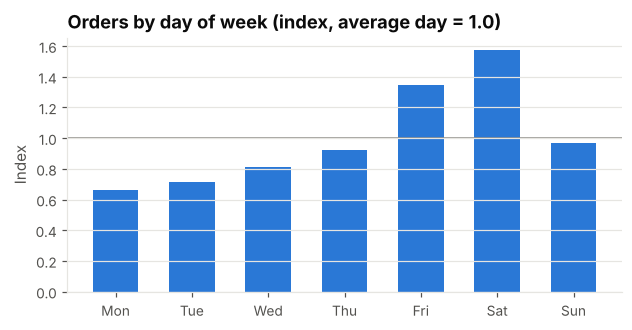

In [3]:
o = hist_orders.copy()
o["dow"] = o["day"] % 7
by_dow = o.groupby("dow").size() / hist_orders["day"].nunique() * 7
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.bar(DOW_NAMES, by_dow.values / by_dow.mean(), color=plots.CONTROL, width=0.6)
plots.zero_line(ax, 1.0)
ax.set_title("Orders by day of week (index, average day = 1.0)")
ax.set_ylabel("Index")
plots.save(fig, "01_orders_by_dow");

## 3. Choose the minimum detectable effect (MDE) — a business decision

The MDE is **not** "the effect we expect". It is the smallest effect that would change
the decision. The new image pipeline adds CDN cost and maintenance; product and finance
agreed that **a relative lift below 5% does not pay for it**. So we size the test to
detect a 5% relative lift (11.5% → 12.1%) with 80% power at α = 0.05 (two-sided).

Smaller MDEs get expensive fast, because the required sample grows with 1 / MDE².

In [4]:
alpha, power = 0.05, 0.80
grid = []
for mde in [0.02, 0.03, 0.04, 0.05, 0.06, 0.08, 0.10]:
    n = sample_size_two_proportions(p0, mde, alpha, power)
    grid.append({"relative MDE": f"{mde:.0%}", "absolute MDE (pp)": p0 * mde * 100,
                 "users per arm": n, "total users": 2 * n,
                 "days of enrollment": 2 * n / users_per_day})
pd.DataFrame(grid).style.format({"absolute MDE (pp)": "{:.2f}", "users per arm": "{:,}",
                                 "total users": "{:,}", "days of enrollment": "{:.1f}"}).hide(axis="index")

relative MDE,absolute MDE (pp),users per arm,total users,days of enrollment
2%,0.23,"305,133","610,266",68.0
3%,0.34,"136,197","272,394",30.4
4%,0.46,"76,938","153,876",17.2
5%,0.57,"49,449","98,898",11.0
6%,0.69,"34,485","68,970",7.7
8%,0.92,"19,560","39,120",4.4
10%,1.15,"12,622","25,244",2.8


In [5]:
n_per_arm = sample_size_two_proportions(p0, 0.05, alpha, power)

# Cross-check against statsmodels (Cohen's h, arcsine transform) — should agree within ~1%
h = proportion_effectsize(p0 * 1.05, p0)
n_sm = NormalIndPower().solve_power(effect_size=h, alpha=alpha, power=power, ratio=1.0)
print(f"Users per arm (our formula): {n_per_arm:,}")
print(f"Users per arm (statsmodels): {n_sm:,.0f}")

Users per arm (our formula): 49,449
Users per arm (statsmodels): 49,443


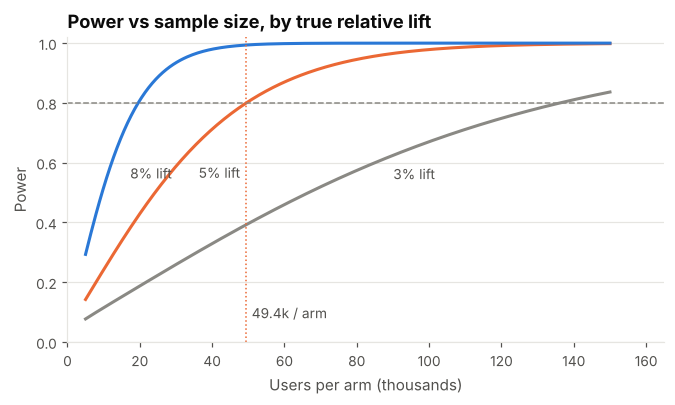

In [6]:
ns = np.linspace(5_000, 150_000, 300)
fig, ax = plt.subplots(figsize=(7, 3.6))
for mde, color in [(0.03, plots.MUTED), (0.05, plots.TREATMENT), (0.08, plots.CONTROL)]:
    pw = np.array([power_two_proportions(n, p0, mde) for n in ns])
    ax.plot(ns / 1000, pw, color=color)
    i = min(np.searchsorted(pw, 0.6), len(ns) - 1)      # direct label where each curve crosses 60%
    ax.annotate(f"{mde:.0%} lift", xy=(ns[i] / 1000, pw[i]), xytext=(12, -2), textcoords="offset points",
                va="top", color=plots.TEXT_2, fontsize=9)
ax.axhline(0.8, color=plots.MUTED, lw=1, ls="--")
ax.axvline(n_per_arm / 1000, color=plots.TREATMENT, lw=1, ls=":")
ax.text(n_per_arm / 1000 + 1.5, 0.08, f"{n_per_arm/1000:.1f}k / arm", color=plots.TEXT_2, fontsize=9)
ax.set_xlim(0, 165)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Users per arm (thousands)")
ax.set_ylabel("Power")
ax.set_title("Power vs sample size, by true relative lift")
plots.save(fig, "01_power_curve");

## 4. Runtime: from users to days

In [7]:
days_needed = 2 * n_per_arm / users_per_day
enroll_days = int(np.ceil(days_needed / 7) * 7)
achieved_n = enroll_days * users_per_day / 2
print(f"Days of enrollment strictly needed: {days_needed:.1f}")
print(f"Rounded up to whole weeks:          {enroll_days} days  (~{achieved_n:,.0f} users per arm)")
print(f"Power at that size for a 5% lift:   {power_two_proportions(achieved_n, p0, 0.05):.1%}")
print(f"MDE at 80% power at that size:      {mde_for_sample_size(int(achieved_n), p0):.2%}")

Days of enrollment strictly needed: 11.0
Rounded up to whole weeks:          14 days  (~62,782 users per arm)
Power at that size for a 5% lift:   88.4%
MDE at 80% power at that size:      4.43%


Timeline:

* **Days 0–13** — enroll users (2 full weeks).
* **Day 21** — primary read-out: the last enrollee's 7-day window closes on day 20.
* **Days 21–27** — keep the test running. A visual redesign is a textbook novelty-effect
  risk; we pre-commit to checking whether the effect holds in users' 2nd–4th weeks before
  shipping (notebook 04).

## 5. Verify the power calculation by simulation

Formulas rest on a normal approximation. A quick check: resample real historical users
into two arms, inject a 5% lift into one, run the planned test, and count how often it
comes out significant. With **no** injected lift the same procedure gives the false
positive rate, which must be ≈ 5%. (This is also a cheap A/A test of the pipeline.)

In [8]:
rng = np.random.default_rng(1)
conv = hist["converted"].to_numpy()
n = int(achieved_n)

def simulated_rejection_rate(lift, n_sims=2_000):
    hits = 0
    for _ in range(n_sims):
        c = rng.choice(conv, n)
        t = rng.choice(conv, n)
        # inject the lift: flip non-converters to converters with prob q so E[p_t] = p0 (1 + lift)
        q = p0 * lift / (1 - p0)
        t = np.where((t == 0) & (rng.random(n) < q), 1, t)
        pc, pt = c.mean(), t.mean()
        pp = (pc + pt) / 2
        z = (pt - pc) / np.sqrt(pp * (1 - pp) * 2 / n)
        hits += abs(z) > 1.96
    return hits / n_sims

aa = simulated_rejection_rate(0.0)
ab = simulated_rejection_rate(0.05)
print(f"A/A false positive rate (target 5%):  {aa:.1%}")
print(f"Simulated power for 5% lift (formula {power_two_proportions(n, p0, 0.05):.1%}): {ab:.1%}")

A/A false positive rate (target 5%):  5.0%
Simulated power for 5% lift (formula 88.4%): 89.1%


## 6. Can CUPED buy a shorter test?

CUPED subtracts the part of the metric predicted by a **pre-experiment** covariate
(here: each user's orders in the 90 days before the test). Variance falls by ρ², where ρ
is the correlation between metric and covariate, and the required sample falls by the
same fraction.

In [9]:
_, theta, reduction = cuped(hist["converted"], hist["pre_orders_90d"])
print(f"θ = {theta:.4f}; variance reduction = {reduction:.1%}")
print(f"Users per arm with CUPED: {n_per_arm * (1 - reduction):,.0f}  (vs {n_per_arm:,})")

θ = 0.0369; variance reduction = 5.0%
Users per arm with CUPED: 46,986  (vs 49,449)


Only a ~5% saving. Pizza ordering is sparse (most users order 0–2 times a quarter), so the
pre-period predicts a 7-day binary outcome weakly. **CUPED is not magic** — it shines on
dense metrics like revenue per active user with a long, stable history. We keep the
2-week plan and use CUPED in the analysis only as a precision bonus.

## 7. Is the test big enough for the segment question?

The decision will also rest on platform-level effects, so check their precision now rather than
discover it later. Each platform gets only part of the sample, and an **interaction** (the
difference between two segment effects) has roughly twice the variance of a single segment's
effect, so it needs far more data to detect at the same size.

In [10]:
share = hist["platform"].value_counts(normalize=True)
rows = []
for plat in ["iOS", "Android"]:
    p_seg = hist.loc[hist.platform == plat, "converted"].mean()
    n_seg = int(achieved_n * share[plat])
    rows.append({"segment": plat, "users per arm": n_seg, "baseline": p_seg,
                 "MDE at 80% power": mde_for_sample_size(n_seg, p_seg)})
seg_power = pd.DataFrame(rows).set_index("segment")
# interaction: SE of (lift_iOS - lift_Android) ≈ sqrt(se_iOS² + se_Android²); MDE scales the same way
seg_power.loc["iOS − Android difference", "MDE at 80% power"] = np.hypot(*seg_power["MDE at 80% power"].iloc[:2])
seg_power.style.format({"users per arm": "{:,.0f}", "baseline": "{:.2%}", "MDE at 80% power": "{:.1%}"}, na_rep="")

,users per arm,baseline,MDE at 80% power
segment,,,
iOS,"34,677",12.37%,5.7%
Android,"28,104",10.39%,7.0%
iOS − Android difference,,,9.1%


So on 7-day conversion we can detect platform effects of ~6–7% and a platform *difference* of
~9%. Smaller reversals would go unseen; that is a known blind spot, not a finding of "no
difference". The weeks 2–4 metric pools three weeks of orders per user and is more precise than
this (it turned out ample: notebook 05).

## 8. Pre-registration (frozen before launch)

| Item | Decision |
|---|---|
| Hypothesis | Menu v2 raises 7-day order conversion |
| Randomization | User-level, 50/50, hash(salt + user_id) |
| Primary metric | 7-day order conversion |
| α / power / MDE | 0.05 two-sided / 80% / 5% relative (≈ 0.57 pp) |
| Sample | ≈ 63k users per arm (14 days of enrollment) |
| Read-out | Day 21, fixed horizon. **No decisions from the live dashboard.** |
| Guardrails (non-inferiority, judged on the 95% CI bound) | **Load time:** p75 of per-user median menu load time must not rise > 10% (upper CI bound ≤ +10%). **AOV:** must not fall > 2% (lower CI bound ≥ −2%). |
| Novelty check / decision metric | Orders per user-day on days 7–27 after exposure ("weeks 2–4"), ratio metric with delta-method CI, read after day 27 |
| Pre-registered segment | **Platform (iOS vs Android).** Mechanism: the photo-heavy page is heavier, and our Android base skews to lower-end devices. |
| Ship rule (per pre-registered segment) | Ship to a segment if its weeks 2–4 effect has a 95% CI above 0 **and** both guardrails pass in that segment. Never ship to a segment that is significantly harmed. |

The 5% MDE sizes the test; it is **not** part of the ship rule. (Using it as a ship threshold
would also be comparing different metrics: it was set on 7-day conversion.)

Two things this table is **not**: it is not a promise the effect is 5% (that is the MDE), and
it must not be reverse-engineered after the fact as "observed power" — post-hoc power is a
monotone transform of the p-value and adds no information.